> **Bản PyTorch** của `examples/2. CNN + MLP/3_Emotion_Reg_CNN.ipynb` (Keras). Người chuyển: TV2 – Lê Phan Nguyên Hải. Notebook khuôn của BTL03.
>
> **Thay đổi so với bản Keras**

> - Bản gốc đọc `fer2013_training_onehot.csv`, `fer2013_publictest_onehot.csv` (mỗi dòng 2304 pixel thô + 7 cột one-hot). Hai file này là `fer2013.csv` (Kaggle) đổi định dạng, nên bản PyTorch đọc thẳng `fer2013.csv` và lọc theo cột `Usage` (`Training` → train, `PublicTest` → test). Pixel giữ nguyên 0–255 như bản gốc; ô dưới in 3 pixel đầu để đối chiếu với output Keras (`70, 80, 82`).
> - Ảnh `(N, 48, 48, 1)` → `(N, 1, 48, 48)`; nhãn dùng cột `emotion` (chỉ số lớp), không cần one-hot.
> - `Conv2D(padding='valid')` → `nn.Conv2d(..., padding=0)`; kích thước: 48 → 46 → pool 23 → 21 → 19 → pool 9, `Flatten` = 218·9·9 = 17 658. Giữ nguyên số filter 218 như bản gốc.
> - `Adam(lr=0.0001)` → `torch.optim.Adam(lr=0.0001)`; khởi tạo trọng số giống Keras (glorot_uniform).

# Overview
- FER2013 dataset (face images + facial expression)
  + Goal: classifying facial exprression
  + Input: a 48x48 image
  + Output: facial expression (angry, disgust, fear, happy, neutral, sad, and surprise)
- Defining an CNN+MLP
- Training and evaluating an CNN+MLP

# Import libraries

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
# cuDNN mặc định chọn thuật toán nhanh nhưng không tất định -> chạy lại cùng seed vẫn ra số hơi khác.
# Tắt để mỗi lần Run All cho cùng kết quả (chậm hơn một chút).
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Keras tự dùng GPU nếu có; PyTorch phải chọn thiết bị và chuyển model, dữ liệu sang thiết bị đó
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
import pandas as pd

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Keras có sẵn các hàm này; PyTorch thì tự viết vòng lặp. Mỗi notebook tự chứa các hàm dưới đây (chép từ khuôn), không phụ thuộc file code nào khác.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append((name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Keras khởi tạo Dense/Conv2D bằng glorot_uniform và bias = 0; PyTorch mặc định dùng kaiming_uniform.
    Khởi tạo giống Keras để kết quả sát bản gốc (nhất là khi đầu vào là pixel thô 0–255)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện; trả về (loss, accuracy) trung bình trên tập train như Keras in ra."""
    model.train()                      # bật Dropout
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(): trả về (loss, accuracy) trên cả tập."""
    model.eval()                       # tắt Dropout
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += loss_fn(logits, y).item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    """Tương đương model.fit(..., validation_data=...): in mỗi epoch giống Keras, trả về history."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for k, v in zip(history, (loss, acc, val_loss, val_acc)):
            history[k].append(v)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - accuracy: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
    return history


def predict(model, x, batch_size=512):
    """Tương đương model.predict(): trả về xác suất softmax dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out)


def plot_history(history):
    """Vẽ loss/accuracy theo epoch từ history (Keras trả về History.history, ở đây là dict)."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(['loss', 'accuracy']):
        ax[i].plot(range(1, len(history[m]) + 1), history[m], label='train')
        ax[i].plot(range(1, len(history['val_' + m]) + 1), history['val_' + m], label='validation')
        ax[i].set_xlabel('epoch'); ax[i].set_ylabel(m); ax[i].legend(); ax[i].grid(alpha=.3)
    plt.show()


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader (thay cho việc truyền thẳng x, y vào model.fit)."""
    ds = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

In [3]:
num_classes = 7   # angry, disgust, fear, happy, sad, surprise, neutral (thứ tự nhãn của Kaggle)

# (1) Data
Đặt `fer2013.csv` cạnh notebook, hoặc để ở `BTL02/data/fer2013.csv` của repo (xem `PHAN_CONG_NHIEM_VU.md` mục 3).

In [4]:
candidates = ['fer2013.csv', '../../../BTL02/data/fer2013.csv']
fer_path = next(p for p in candidates if os.path.exists(p))
df = pd.read_csv(fer_path)
print(fer_path, df.shape)
print(df['Usage'].value_counts())

def load_split(usage):
    sub = df[df['Usage'] == usage]
    x = np.stack([np.fromstring(p, dtype=np.float32, sep=' ') for p in sub['pixels']])   # (N, 2304)
    return x, sub['emotion'].to_numpy()

x_training, y_training = load_split('Training')      # = fer2013_training_onehot.csv
x_testing, y_testing = load_split('PublicTest')      # = fer2013_publictest_onehot.csv
print('3 pixel đầu của ảnh train đầu tiên:', x_training[0, :3])   # Keras gốc: [70, 80, 82]

../../../BTL02/data/fer2013.csv (35887, 3)
Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64


3 pixel đầu của ảnh train đầu tiên: [70. 80. 82.]


In [5]:
n_inputs = 2304
img_dim = 48

# Keras: (N, 48, 48, 1)  ->  PyTorch: (N, 1, 48, 48)
x_training = x_training.reshape(x_training.shape[0], 1, img_dim, img_dim)
x_testing = x_testing.reshape(x_testing.shape[0], 1, img_dim, img_dim)
print(x_training.shape, y_training.shape, x_testing.shape, y_testing.shape)

(28709, 1, 48, 48) (28709,) (3589, 1, 48, 48) (3589,)


# (2) Declare model

In [6]:
from collections import OrderedDict

model = nn.Sequential(OrderedDict([
    # conv, pooling layers + dropout
    ('conv1_1', nn.Conv2d(1, 64, 3, padding=1)), ('relu1_1', nn.ReLU()),       # 'same'
    ('conv1_2', nn.Conv2d(64, 64, 3, padding=0)), ('relu1_2', nn.ReLU()),      # 'valid'
    ('pool1', nn.MaxPool2d(2)), ('conv_dropout1', nn.Dropout(0.25)),
    ('conv2_1', nn.Conv2d(64, 128, 3, padding=1)), ('relu2_1', nn.ReLU()),
    ('conv2_2', nn.Conv2d(128, 128, 3, padding=0)), ('relu2_2', nn.ReLU()),
    ('conv2_3', nn.Conv2d(128, 218, 3, padding=1)), ('relu2_3', nn.ReLU()),
    ('conv2_4', nn.Conv2d(218, 218, 3, padding=0)), ('relu2_4', nn.ReLU()),
    ('pool2', nn.MaxPool2d(2)), ('conv_dropout2', nn.Dropout(0.25)),
    # similar to the MLP example!
    ('flatten', nn.Flatten()),
    ('fc1', nn.Linear(218 * 9 * 9, 1024)), ('relu_fc1', nn.ReLU()), ('fc_dropout1', nn.Dropout(0.5)),
    ('fc3', nn.Linear(1024, num_classes)),     # 7 lớp, softmax nằm trong CrossEntropyLoss
])).to(device)
init_like_keras(model)
summary(model, (1, 48, 48))   # Keras: 19,028,287 tham số

Layer (type)                        Output Shape               Param #
conv1_1 (Conv2d)                    (None, 64, 48, 48)             640
relu1_1 (ReLU)                      (None, 64, 48, 48)               0
conv1_2 (Conv2d)                    (None, 64, 46, 46)          36,928
relu1_2 (ReLU)                      (None, 64, 46, 46)               0
pool1 (MaxPool2d)                   (None, 64, 23, 23)               0
conv_dropout1 (Dropout)             (None, 64, 23, 23)               0
conv2_1 (Conv2d)                    (None, 128, 23, 23)         73,856
relu2_1 (ReLU)                      (None, 128, 23, 23)              0
conv2_2 (Conv2d)                    (None, 128, 21, 21)        147,584
relu2_2 (ReLU)                      (None, 128, 21, 21)              0
conv2_3 (Conv2d)                    (None, 218, 21, 21)        251,354
relu2_3 (ReLU)                      (None, 218, 21, 21)              0
conv2_4 (Conv2d)                    (None, 218, 19, 19)        427,934
relu2_

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

**Keras → PyTorch:** `model.compile(loss='categorical_crossentropy', ...)` + lớp cuối `softmax` được thay bằng lớp cuối trả về *logits* và `nn.CrossEntropyLoss()` (đã gồm log-softmax). Vì vậy nhãn là số nguyên lớp, không cần one-hot (`to_categorical`). Keras mặc định trộn dữ liệu mỗi epoch → `shuffle=True` cho tập train.

In [7]:
loss_fn = nn.CrossEntropyLoss()
lr = 0.0001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

batch_size = 128
epochs = 15
train_loader = make_loader(x_training, y_training, batch_size, shuffle=True)
test_loader = make_loader(x_testing, y_testing, batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs)
print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 1/15 - 15.8s - loss: 2.3658 - accuracy: 0.2379 - val_loss: 1.8052 - val_accuracy: 0.2828


Epoch 2/15 - 15.6s - loss: 1.7307 - accuracy: 0.3079 - val_loss: 1.6300 - val_accuracy: 0.3976


Epoch 3/15 - 15.6s - loss: 1.6137 - accuracy: 0.3734 - val_loss: 1.5032 - val_accuracy: 0.4252


Epoch 4/15 - 15.7s - loss: 1.5195 - accuracy: 0.4148 - val_loss: 1.4325 - val_accuracy: 0.4583


Epoch 5/15 - 15.7s - loss: 1.4161 - accuracy: 0.4592 - val_loss: 1.3482 - val_accuracy: 0.4812


Epoch 6/15 - 15.7s - loss: 1.3278 - accuracy: 0.4960 - val_loss: 1.3190 - val_accuracy: 0.5052


... (5 outputs left out)

Epoch 12/15 - 15.7s - loss: 0.7787 - accuracy: 0.7184 - val_loss: 1.1942 - val_accuracy: 0.5740


Epoch 13/15 - 15.7s - loss: 0.6746 - accuracy: 0.7538 - val_loss: 1.2132 - val_accuracy: 0.5874


Epoch 14/15 - 15.7s - loss: 0.5954 - accuracy: 0.7867 - val_loss: 1.2428 - val_accuracy: 0.5887


Epoch 15/15 - 15.8s - loss: 0.5027 - accuracy: 0.8207 - val_loss: 1.2786 - val_accuracy: 0.5954
> training time is 3.9206 minutes


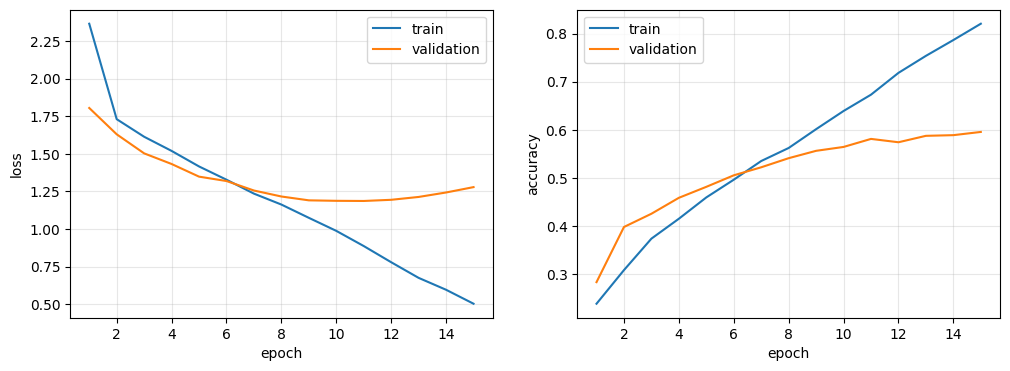

In [8]:
plot_history(history)

### Training time
- Bản Keras gốc (GTX 1080): 6.1120 phút cho 15 epoch, test accuracy 0.5954
- Bản PyTorch: xem kết quả ô trên (RTX 4060 Laptop)

# (4) Evaluate trained model

In [9]:
score = evaluate(model, test_loader, loss_fn)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 1.278568200528306
Test accuracy: 0.5954304820284202


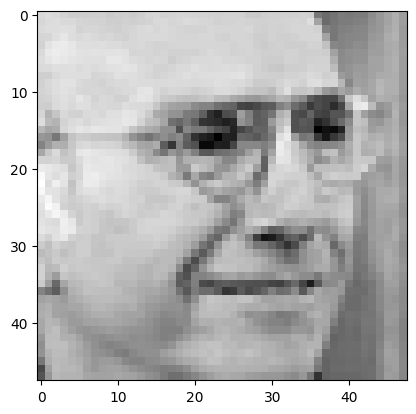

> testing image index: 1969
> true emotion: happy
> predicted emotion: happy


In [10]:
EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']

def get_emotion(label_or_probs):
    """Nhận chỉ số lớp hoặc vector xác suất, trả về tên cảm xúc (giống hàm get_emotion bản gốc)."""
    return EMOTIONS[int(np.argmax(label_or_probs)) if np.ndim(label_or_probs) else int(label_or_probs)]

img_indx = np.uint32(np.random.rand() * (x_testing.shape[0] - 1))
sample = x_testing[img_indx]
pred_cls = predict(model, sample.reshape(1, 1, 48, 48))

plt.imshow(sample.reshape(48, 48), cmap='gray')
plt.show()
print('> testing image index: %d\n> true emotion: %s\n> predicted emotion: %s'
      % (img_indx, get_emotion(y_testing[img_indx]), get_emotion(pred_cls)))